# La componente non spiegata dai fattori è prevedibile?
## Fama–French, machine learning e portafogli azionari italiani

**Domanda di ricerca.** La componente di rendimento non spiegata dai modelli fattoriali contiene informazioni prevedibili attraverso tecniche di machine learning, tali da migliorare l’efficienza dei portafogli out-of-sample?

*Does the component of asset returns unexplained by factor models contain predictable information that can be exploited through machine learning to improve out-of-sample portfolio efficiency?*

Il protocollo confronta quattro stime del rendimento atteso quotidiano sotto gli stessi vincoli. Il criterio empirico è la performance netta fuori campione, interpretata insieme all’errore di previsione e all’incertezza statistica. Il confronto principale usa Ridge per entrambi i modelli ML. Random Forest e XGBoost sono specificazioni predittive secondarie a iperparametri fissi. Il campione di sei azioni italiane è intenzionalmente piccolo e fisso. La scelta retrospettiva di titoli con storico completo può introdurre survivorship bias.

In [1]:
from pathlib import Path
import os
import sys

cwd = Path.cwd()
study = next(p for p in [cwd / "research", cwd] if (p / "models.py").is_file())
candidates = [os.environ.get("QUANT_PORTFOLIO_REPO"), study.parent,
              Path.home() / "quant-portfolio-optimizer"]
repo = next(Path(p).expanduser().resolve() for p in candidates
            if p and (Path(p).expanduser() / "src" / "optimization.py").is_file())
sys.path[:0] = [str(study), str(repo)]

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from config import Config
from data_inputs import FACTORS, load_dataset
from models import ALGORITHMS, ANNUAL, PRIMARY, BENCH, run
from evaluation import (econometrics, forecast_metrics, inference, performance,
                        portfolio_exposures, differential_attribution)
from reporting import Reports, descriptive, forecast_figures, allocations, realized_figures, robustness

REFRESH_DATA = False
cfg = Config(
    assets=("ENI.MI", "ENEL.MI", "ISP.MI", "UCG.MI", "G.MI", "TRN.MI"),
    start="2019-10-03", end="2025-12-31", benchmark="FTSEMIB.MI", currency="EUR",
    test_start="2023-01-03", training_years=3, test_years=1,
    rebalance_days=63, cost_bps=15, max_weight=.40, seed=42,
)
out = Reports(study / "results")
display(cfg)

2026-11-26 19:13:30.801 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-26 19:13:30.802 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


Config(assets=('ENI.MI', 'ENEL.MI', 'ISP.MI', 'UCG.MI', 'G.MI', 'TRN.MI'), start='2019-10-03', end='2025-12-31', benchmark='FTSEMIB.MI', currency='EUR', test_start='2023-01-03', training_years=3, test_years=1, rebalance_days=63, cost_bps=15, max_weight=0.4, seed=42, hac_lags=10, bootstrap_reps=2000, block_days=21)

## 1. Dati, valute e calendario

Il motore del repository acquisisce prezzi rettificati Yahoo per azioni, benchmark e cambio EUR/USD. I prezzi azionari e il benchmark sono in EUR; $r_t=P_t/P_{t-1}-1$. Il benchmark primario è FTSEMIB.MI, l’indice FTSE MIB a rendimento di prezzo, con copertura completa. L’ETF ad accumulazione iShares FTSE MIB UCITS ETF (CSMIB.MI, IE00B53L4X51) segue il FTSE MIB Total Return. Il feed Yahoo ha sedute mancanti per CSMIB.MI, ETFMIB.MI e XMIB.MI e una lacuna prolungata per IMIB.MI nel 2025. Riportiamo un confronto supplementare sul prefisso continuo CSMIB.MI; le sue quotazioni riflettono anche le spese del fondo e il tracking. L’indice primario esclude i dividendi e può quindi favorire relativamente i portafogli con prezzi rettificati. [Borsa Italiana](https://www.borsaitaliana.it/borsa/etf/scheda/IE00B53L4X51-ETFP.html)

I fattori della Kenneth French Data Library sono europei e in USD. Con $S_t$ espresso in USD per EUR, $q_t=S_{t-1}/S_t$, il rendimento del mercato EUR è $(1+r^{USD}_{M,t})q_t-1$. I premi long–short SMB e HML sono scalati per $q_t$; da quello del mercato si sottrae l’€STR. Il tasso giornaliero al tempo $t$ usa l’ultimo fixing disponibile alla chiusura precedente, su base ACT/360. La mappatura ECB usa il calendario delle osservazioni della serie e assume la normale pubblicazione la mattina del successivo giorno TARGET. I fattori entrano nelle regressioni soltanto se l’intervallo coincide con quello dei rendimenti italiani. Il portafoglio conserva le sedute italiane effettive anche quando i fattori mancano. I parametri rispettano il ritardo prudenziale di due mesi del repository; i dati scaricati sono una singola versione storica, per cui il ritardo non elimina il rischio di revisioni.

Riferimenti per i dati. [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) · [BCE, €STR](https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_short-term_rate/html/index.en.html)

In [2]:
panel, provenance = load_dataset(cfg, study / "data", REFRESH_DATA)
display(pd.Series({k: v for k, v in provenance.items() if k not in ("quotes", "configuration")}))
display(panel.tail())
returns = panel[["return:" + s for s in cfg.assets]].set_axis(cfg.assets, axis=1)
factors = panel[FACTORS + ["RF"]].dropna()
display(out.table("data_coverage", panel.count().to_frame("Observations")))

acquired_utc                 2026-11-26T18:11:37.797951+00:00
benchmark_symbol                                   FTSEMIB.MI
benchmark_basis        Index price return, dividends excluded
source_prices_fx                   Yahoo Finance via yfinance
source_factors                    Kenneth French Data Library
source_rf                           ECB EST.B.EU000A2X2A25.WT
factor_matched_days                                      1559
dtype: object

,price:ENI.MI,price:ENEL.MI,price:ISP.MI,price:UCG.MI,price:G.MI,price:TRN.MI,price:FTSEMIB.MI,return:ENI.MI,return:ENEL.MI,return:ISP.MI,...,return:G.MI,return:TRN.MI,return:FTSEMIB.MI,MKT-RF,SMB,HML,RF,ESTR percent at close,EURUSD=X,aux:CSMIB.MI
Date,,,,,,,,,,,,,,,,,,,,,
2025-12-19,15.195516,8.306341,5.504889,66.132965,34.213116,8.638922,44758.0,0.011195,0.013454,0.005099,...,0.015345,0.012844,0.006635,0.003971,-0.001702,0.000701,0.000054,1.931,1.172567,216.899994
2025-12-22,15.342711,8.273070,5.475103,65.551041,34.490807,8.571655,44594.0,0.009687,-0.004005,-0.005411,...,0.008117,-0.007786,-0.003664,0.004645,0.005608,-0.000300,0.000161,1.933,1.170809,NaN
2025-12-23,15.254776,8.335811,5.464864,65.644905,34.356750,8.644688,44607.0,-0.005731,0.007584,-0.001870,...,-0.003887,0.008520,0.000292,0.000601,-0.000498,-0.000498,0.000054,1.932,1.176595,216.199997
2025-12-29,15.270067,8.378588,5.434147,65.072365,34.059910,8.656219,44436.0,0.001002,0.005132,-0.005621,...,-0.008640,0.001334,-0.003833,NaN,NaN,NaN,0.000322,1.926,1.177274,NaN
2025-12-30,15.426821,8.438475,5.511405,66.564720,34.232265,8.700422,44945.0,0.010265,0.007148,0.014217,...,0.005060,0.005106,0.011455,0.003635,-0.001700,0.004800,0.000053,1.934,1.177288,NaN


,Observations
price:ENI.MI,1586
price:ENEL.MI,1586
price:ISP.MI,1586
price:UCG.MI,1586
price:G.MI,1586
price:TRN.MI,1586
price:FTSEMIB.MI,1586
return:ENI.MI,1585
return:ENEL.MI,1585
return:ISP.MI,1585


## 2. Specificazione econometrica e costruzione dei target

Per ciascun titolo stimiamo $r_{i,s}-r_{f,s}=\alpha_i+\beta_i^\top F_s+\varepsilon_{i,s}$ via OLS con intercetta. Il premio di mercato misura l’esposizione azionaria; SMB e HML approssimano rispettivamente le componenti dimensione e valore. Un buon $R^2$ misura la spiegazione contemporanea. La previsione richiede inoltre previsioni utili dei fattori o della parte non spiegata.

- **Historical.** $\widehat\mu_{i,t}=\overline r_{i,t}$ è la media aritmetica su 756 sedute. La media è sensibile a outlier, cambi di regime ed errore campionario.
- **FF3.** $\widehat\mu_{i,t}=\widehat r_{f,t+1}+\widehat\beta_{i,t}^\top\overline F_t$, con premi medi e beta stimati nella stessa finestra di osservazioni pubblicate. L’alpha storico rimane un parametro descrittivo. La sua persistenza è una questione empirica.
- **Pure ML.** $\widehat\mu_{i,t}=g_t(X_{i,t})$, con target $r_{i,t+1}$. Le nove feature del repository sono momentum a 21/63/126/252 sedute, volatilità a 21/63, drawdown da massimo a 63 e momentum a 63 dell’universo equiponderato e relativo. Tutte si fermano alla chiusura di $t$.
- **Hybrid FF3–ML.** Definiamo $a_{i,s}=r_{i,s}-r_{f,s}-(\widehat\beta_{i,s-1}^{\,252})^\top F_s$. L’intercetta $\alpha_i$ è l’extra-rendimento condizionale medio nel fit. Il residuo OLS è $\widehat\varepsilon_{i,s}=r_{i,s}-r_{f,s}-\widehat\alpha_i-\widehat\beta_i^\top F_s$. Il target $a_{i,s}$ conserva l’eventuale alpha ed è calcolato con beta stimati prima di $s$ su 252 sedute, applicando il ritardo di pubblicazione. L’ibrido prevede $\widehat r_{f,t+1}+\widehat\beta_{i,t}^\top\overline F_t+h_t(X_{i,t})$. Il termine $h_t$ può già incorporare una componente media anomala.

La finestra più corta dei beta del target permette di costruire abbastanza etichette per il primo fit; la componente sistematica prevista usa invece la finestra principale e quindi può avere esposizioni diverse. I modelli ML sono pooled e stimano la stessa funzione per tutti i titoli. Entrambi usano le stesse righe con target osservabili e le stesse feature; la disponibilità del target ibrido determina il taglio comune. Ridge minimizza $\sum (y-Xb)^2+10\|b\|_2^2$ dopo standardizzazione nel training. Random Forest riduce la varianza mediando alberi; XGBoost aggiorna sequenzialmente la previsione con alberi regolarizzati. I parametri di questi due modelli provengono dal repository. Le specificazioni sono fisse, senza ricerca di iperparametri. Il test cronologico misura anche l’eventuale instabilità della relazione tra feature e target.

In [3]:
result = run(panel, cfg)
display(out.table("decision_timing", result.fit_audit))
display(out.table("target_timing", result.target_audit).tail())

,Decision,Execution,Window start,Last factor,Last ML label,ML rows
0,2023-01-02,2023-01-03,2020-01-20,2022-11-02,2022-11-02,3156
1,2023-03-30,2023-03-31,2020-04-20,2023-01-30,2023-01-30,3522
2,2023-06-30,2023-07-03,2020-07-17,2023-04-28,2023-04-28,3888
3,2023-09-28,2023-09-29,2020-10-14,2023-07-28,2023-07-28,4212
4,2023-12-28,2023-12-29,2021-01-15,2023-10-27,2023-10-27,4224
5,2024-03-27,2024-03-28,2021-04-16,2024-01-26,2024-01-26,4212
6,2024-06-27,2024-06-28,2021-07-14,2024-04-26,2024-04-26,4206
7,2024-09-25,2024-09-26,2021-10-11,2024-07-25,2024-07-25,4200
8,2024-12-23,2024-12-27,2022-01-10,2024-10-23,2024-10-23,4206
9,2025-03-27,2025-03-28,2022-04-07,2025-01-27,2025-01-27,4194


,Target date,Beta decision,Beta last factor
1307,2025-12-18,2025-12-17,2025-10-17
1308,2025-12-19,2025-12-18,2025-10-17
1309,2025-12-22,2025-12-19,2025-10-17
1310,2025-12-23,2025-12-22,2025-10-22
1311,2025-12-30,2025-12-29,2025-10-29


## 3. Diagnostica esplorativa e inferenza sugli alpha

Le distribuzioni sono in unità giornaliere. La kurtosis è in eccesso rispetto alla normale. Le correlazioni e le regressioni descrittive usano l’intero campione disponibile e sono a fini interpretativi. Le specificazioni predittive sono state fissate prima di questi risultati. Nei grafici rolling ogni beta precede l’osservazione usata per il target. I test Ljung–Box verificano l’autocorrelazione congiunta fino ai lag indicati; ARCH-LM verifica dipendenza nei quadrati dei residui. Nei campioni fattoriali questi lag contano osservazioni abbinate, quindi possono attraversare sedute mancanti. Un effetto ARCH è informativo sulla varianza condizionale; la domanda primaria riguarda la media.

Per ogni coefficiente si riportano errore standard HAC Newey–West, $t$, $p$ bilaterale e intervallo di confidenza al 95%. $H_0:\alpha_i=0$; il test descrittivo per titolo usa $p<0{,}05$ nominale. La dimensione economica è espressa come $252\widehat\alpha$. Le regressioni non identificano causalità e la significatività in-sample non implica persistenza.

,count,mean,std,skew,kurt,min,median,max
ENI.MI,1585.0,0.000542,0.018311,-1.276565,21.964225,-0.208521,0.001279,0.149307
ENEL.MI,1585.0,0.000520,0.015151,-1.738435,21.601532,-0.198466,0.000580,0.075201
ISP.MI,1585.0,0.001094,0.018838,-0.944428,9.887677,-0.177833,0.001652,0.110903
UCG.MI,1585.0,0.001685,0.024483,-0.358078,6.421133,-0.172600,0.001771,0.137232
G.MI,1585.0,0.000762,0.013835,-0.699496,10.680330,-0.129520,0.001001,0.110601
TRN.MI,1585.0,0.000556,0.013804,-0.896818,11.268636,-0.149458,0.000344,0.078070


,ENI.MI,ENEL.MI,ISP.MI,UCG.MI,G.MI,TRN.MI
ENI.MI,1.000000,0.505100,0.588183,0.520914,0.616725,0.362301
ENEL.MI,0.505100,1.000000,0.562228,0.457399,0.586281,0.660724
ISP.MI,0.588183,0.562228,1.000000,0.829621,0.725278,0.341854
UCG.MI,0.520914,0.457399,0.829621,1.000000,0.641508,0.242827
G.MI,0.616725,0.586281,0.725278,0.641508,1.000000,0.439310
TRN.MI,0.362301,0.660724,0.341854,0.242827,0.439310,1.000000


,MKT-RF,SMB,HML
MKT-RF,1.000000,-0.351133,0.083086
SMB,-0.351133,1.000000,-0.187813
HML,0.083086,-0.187813,1.000000


/Users/giuseppecangemi/quant-portfolio-optimizer/.venv/lib/python3.14/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/Users/giuseppecangemi/quant-portfolio-optimizer/.venv/lib/python3.14/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/Users/giusepp

Coefficient  Annual alpha   HAC SE     HAC t  p-value  \
Asset   Term                                                            
ENI.MI  Alpha      -0.00014      -0.03505  0.00036  -0.38195  0.70255   
        MKT-RF      0.71133           NaN  0.07002  10.15969  0.00000   
        SMB        -0.62329           NaN  0.14371  -4.33699  0.00002   
        HML         1.09234           NaN  0.08872  12.31179  0.00000   
ENEL.MI Alpha       0.00010       0.02529  0.00031   0.32039  0.74871   
        MKT-RF      0.62206           NaN  0.06867   9.05864  0.00000   
        SMB        -0.66590           NaN  0.10212  -6.52046  0.00000   
        HML         0.05116           NaN  0.05910   0.86569  0.38679   
ISP.MI  Alpha       0.00038       0.09603  0.00030   1.26736  0.20522   
        MKT-RF      0.88442           NaN  0.05168  17.11237  0.00000   
        SMB        -0.62672           NaN  0.11168  -5.61193  0.00000   
        HML         0.92886           NaN  0.06823  13.61452  0.00000   
UCG.MI  Alpha       0.00083       0.20989  0.00045   1.86243  0.06273   
        MKT-RF      0.96679           NaN  0.06289  15.37274  0.00000   
        SMB        -0.77887           NaN  0.13475  -5.78011  0.00000   
        HML         1.36349           NaN  0.09289  14.67906  0.00000   
G.MI    Alpha       0.00025       0.06198  0.00024   1.00747  0.31387   
        MKT-RF      0.62726           NaN  0.04700  13.34491  0.00000   
        SMB        -0.40010           NaN  0.10041  -3.98456  0.00007   
        HML         0.59282           NaN  0.06318   9.38343  0.00000   
TRN.MI  Alpha       0.00038       0.09567  0.00029   1.32096  0.18671   
        MKT-RF      0.35108           NaN  0.06571   5.34285  0.00000   
        SMB        -0.80645           NaN  0.16141  -4.99636  0.00000   
        HML        -0.24648           NaN  0.07082  -3.48067  0.00051   

                 CI low  CI high       R²  Adjusted R²     n  
Asset   Term                                                  
ENI.MI  Alpha  -0.00085  0.00058  0.50160      0.50063  1559  
        MKT-RF  0.57400  0.84867  0.50160      0.50063  1559  
        SMB    -0.90518 -0.34139  0.50160      0.50063  1559  
        HML     0.91831  1.26637  0.50160      0.50063  1559  
ENEL.MI Alpha  -0.00051  0.00071  0.36625      0.36503  1559  
        MKT-RF  0.48736  0.75676  0.36625      0.36503  1559  
        SMB    -0.86621 -0.46558  0.36625      0.36503  1559  
        HML    -0.06476  0.16708  0.36625      0.36503  1559  
ISP.MI  Alpha  -0.00021  0.00097  0.56642      0.56559  1559  
        MKT-RF  0.78304  0.98579  0.56642      0.56559  1559  
        SMB    -0.84577 -0.40767  0.56642      0.56559  1559  
        HML     0.79504  1.06269  0.56642      0.56559  1559  
UCG.MI  Alpha  -0.00004  0.00171  0.47993      0.47893  1559  
        MKT-RF  0.84343  1.09015  0.47993      0.47893  1559  
        SMB    -1.04319 -0.51456  0.47993      0.47893  1559  
        HML     1.18130  1.54569  0.47993      0.47893  1559  
G.MI    Alpha  -0.00023  0.00072  0.49841      0.49744  1559  
        MKT-RF  0.53506  0.71945  0.49841      0.49744  1559  
        SMB    -0.59706 -0.20314  0.49841      0.49744  1559  
        HML     0.46890  0.71674  0.49841      0.49744  1559  
TRN.MI  Alpha  -0.00018  0.00094  0.20864      0.20712  1559  
        MKT-RF  0.22219  0.47997  0.20864      0.20712  1559  
        SMB    -1.12305 -0.48985  0.20864      0.20712  1559  
        HML    -0.38539 -0.10758  0.20864      0.20712  1559

LB(5)   LB(10)   LB(21)  LB p(5)  LB p(10)  \
Asset   Series                                                          
ENI.MI  OLS residual     11.1932  29.7975  63.0843   0.0477    0.0009   
        Factor-adjusted   4.6127  17.3962  27.7502   0.4649    0.0660   
ENEL.MI OLS residual      4.5664  14.4448  28.6075   0.4711    0.1537   
        Factor-adjusted   5.8189  15.9154  32.2451   0.3242    0.1021   
ISP.MI  OLS residual     32.6265  37.4871  56.4748   0.0000    0.0000   
        Factor-adjusted  23.7865  28.4195  39.9865   0.0002    0.0015   
UCG.MI  OLS residual     12.5231  16.4826  39.8304   0.0283    0.0866   
        Factor-adjusted  20.1882  23.7661  44.7980   0.0012    0.0082   
G.MI    OLS residual     24.8943  33.4624  42.6538   0.0001    0.0002   
        Factor-adjusted  16.1457  25.9803  38.2057   0.0064    0.0038   
TRN.MI  OLS residual     12.4499  15.3486  36.8136   0.0291    0.1199   
        Factor-adjusted   7.6652  10.0931  23.0094   0.1757    0.4324   

                         LB p(21)   ARCH LM  ARCH p  
Asset   Series                                       
ENI.MI  OLS residual       0.0000  143.3780  0.0000  
        Factor-adjusted    0.1474   85.0668  0.0000  
ENEL.MI OLS residual       0.1237  116.0307  0.0000  
        Factor-adjusted    0.0553   24.1032  0.0073  
ISP.MI  OLS residual       0.0000   88.7655  0.0000  
        Factor-adjusted    0.0075   78.7401  0.0000  
UCG.MI  OLS residual       0.0078   25.4286  0.0046  
        Factor-adjusted    0.0018   30.4140  0.0007  
G.MI    OLS residual       0.0035  109.8978  0.0000  
        Factor-adjusted    0.0122   98.5648  0.0000  
TRN.MI  OLS residual       0.0177  230.8546  0.0000  
        Factor-adjusted    0.3435  100.2458  0.0000

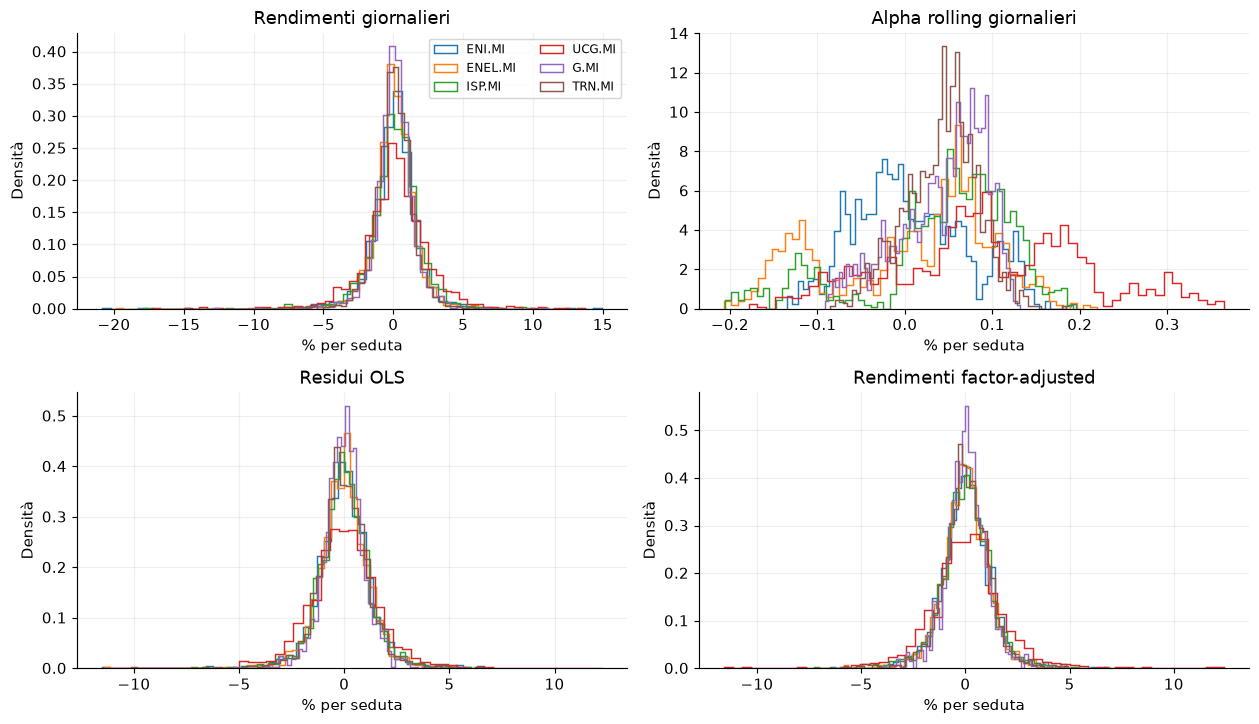

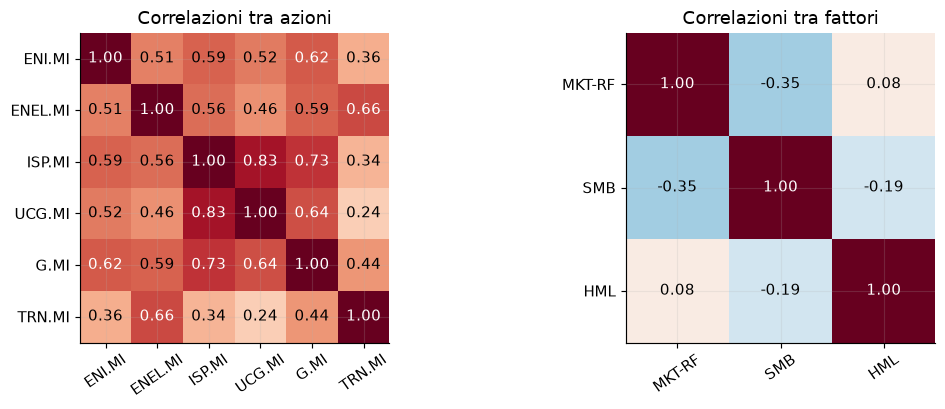

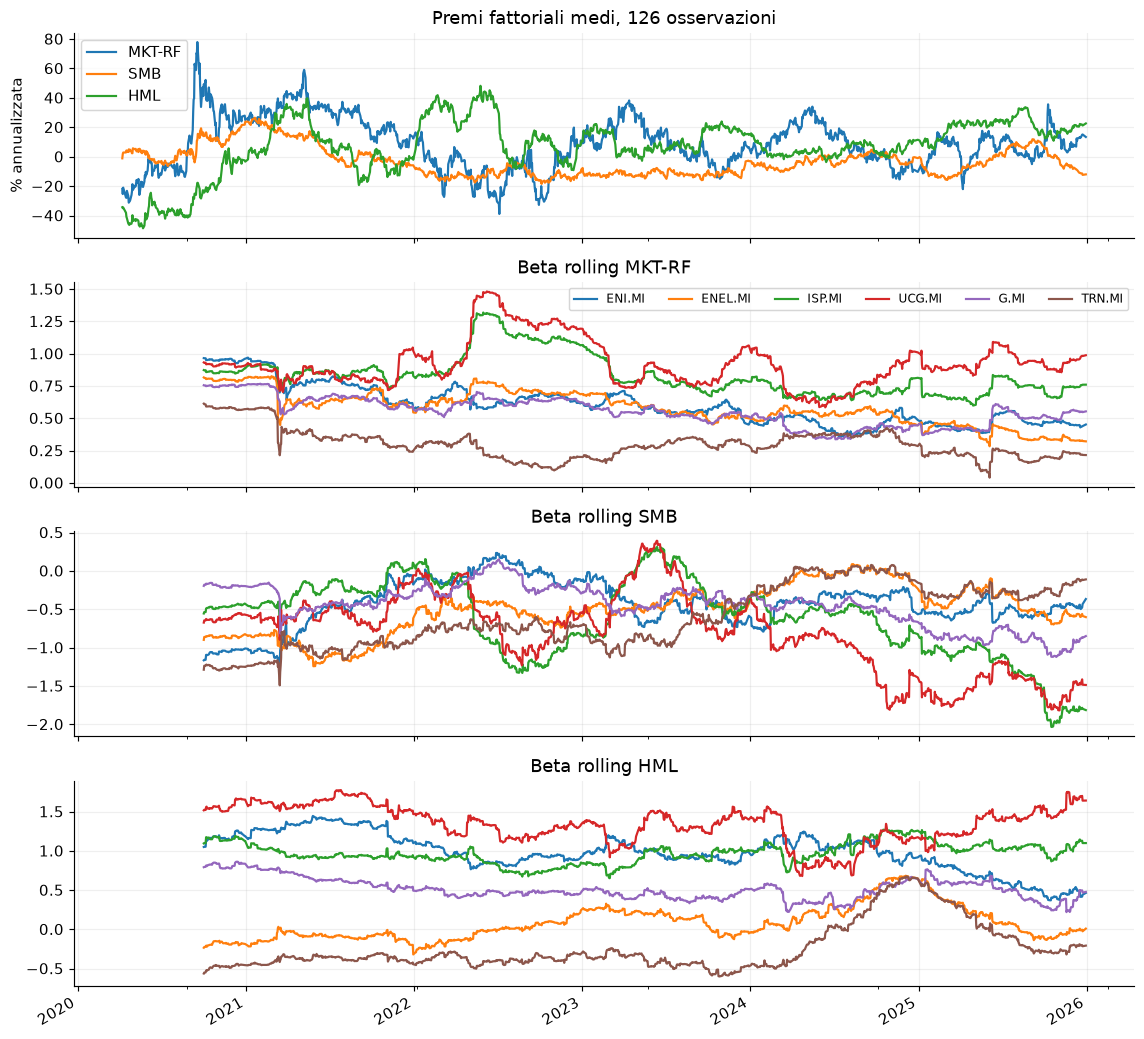

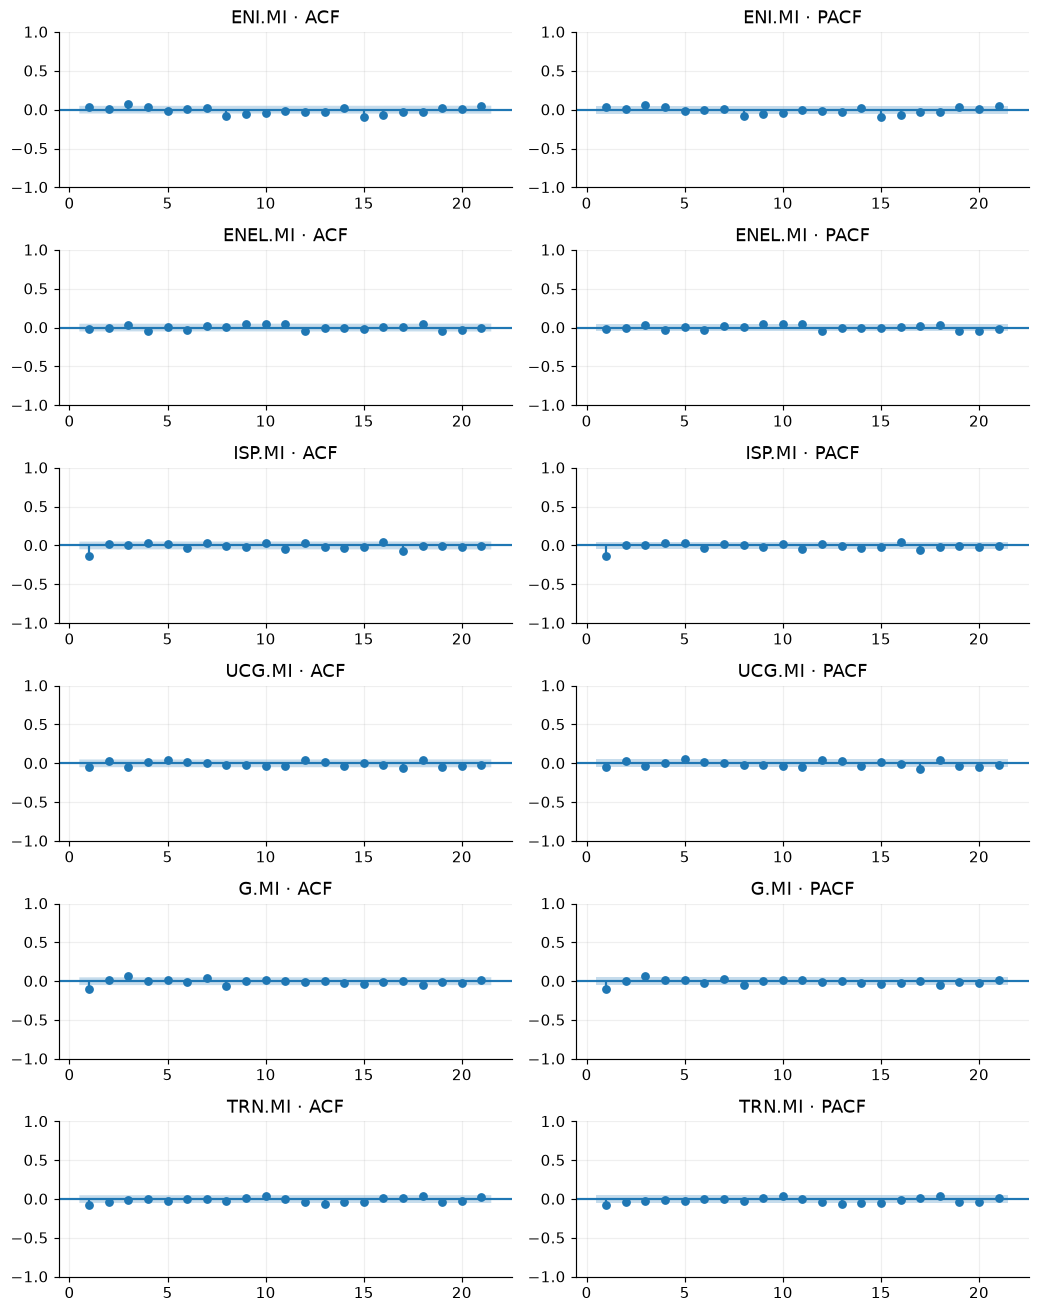

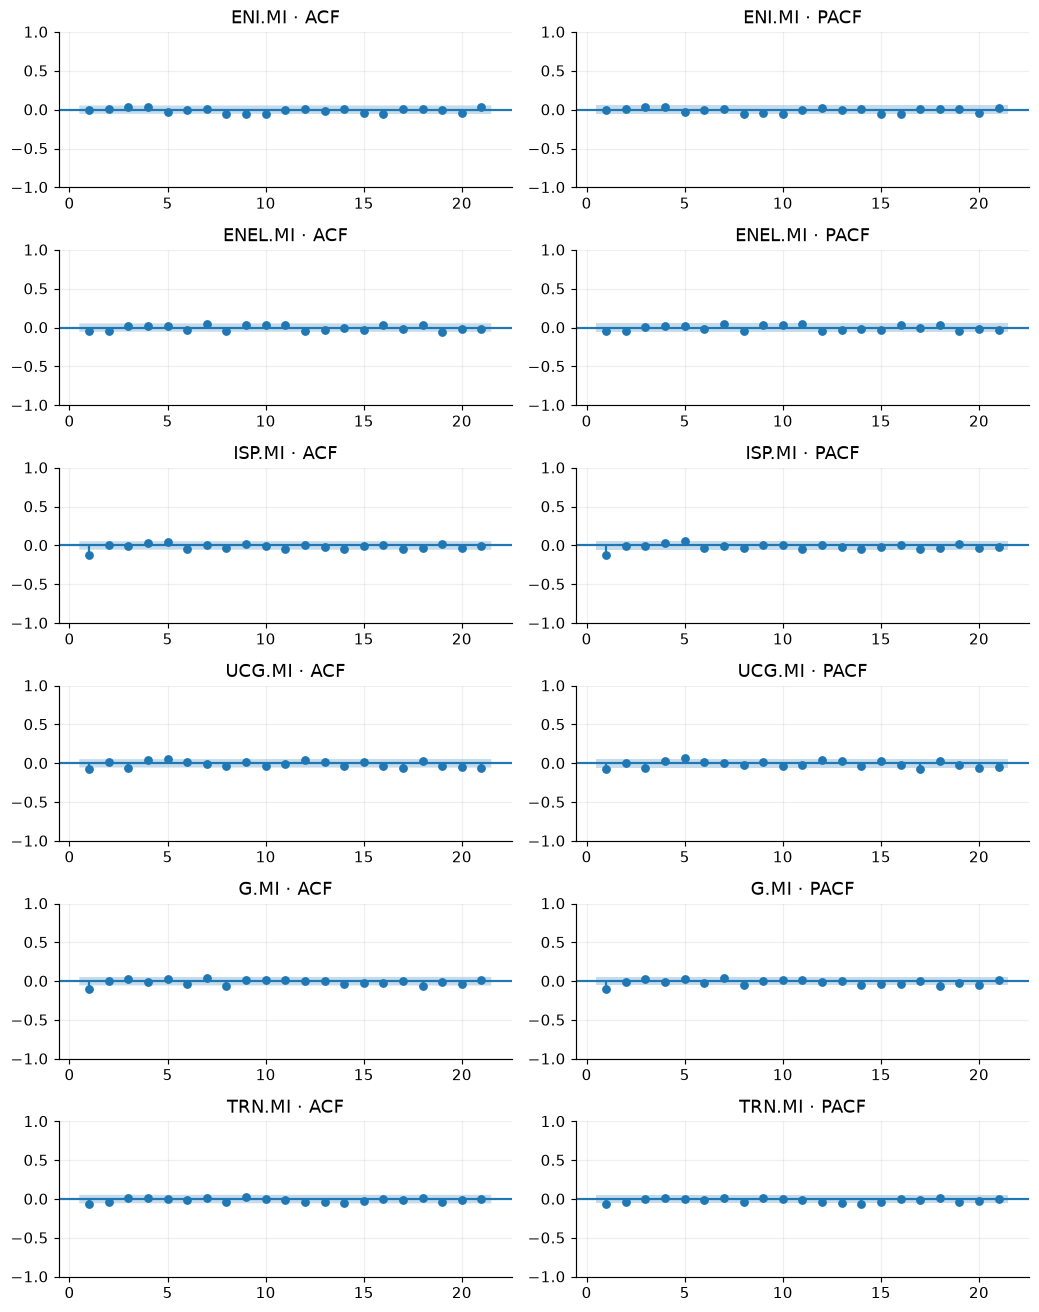

In [4]:
summary = returns.agg(["count", "mean", "std", "skew", "kurt", "min", "median", "max"]).T
display(out.table("descriptive_statistics", summary))
display(out.table("asset_correlations", returns.corr()))
display(out.table("factor_correlations", factors[FACTORS].corr()))
coefs, tests, residuals = econometrics(returns, factors, result.adjusted, cfg.hac_lags)
display(out.table("factor_hac", coefs).round(5))
display(out.table("residual_diagnostics", tests).round(4))
descriptive(out, returns, factors, residuals, result.adjusted, result.alphas, result.betas)

## 4. Previsione fuori campione

La stima viene aggiornata ogni 63 sedute. Tra due stime le feature quotidiane entrano in modelli congelati per prevedere sempre la seduta successiva. Le finestre annuali di test sono disgiunte; dopo la pubblicazione, un’osservazione può entrare solo nel training di una stima successiva. Le previsioni al giorno di esecuzione appartengono alla valutazione predittiva, mentre i rendimenti di portafoglio iniziano dopo la prima esecuzione. Le valutazioni usano lo stesso insieme di osservazioni per tutti i modelli di ciascuna tabella.

Calcoliamo MAE, RMSE, $R^2_{\rm OOS}=1-\sum(y-\widehat y)^2/\sum(y-\widehat y_{\mathrm{base}})^2$, accuratezza del segno ed errore medio come previsione meno realizzato. Pearson e Spearman si calcolano tra i sei titoli a ogni data, con date a predizione costante omesse dal solo IC. Per il target factor-adjusted, i confronti sono il valore zero, equivalente a nessuna correzione, e la media rolling osservabile per titolo. Un segnale che non supera la media può riflettere soprattutto un livello medio. L’IC su sei titoli è rumoroso.

,n,MAE,RMSE,OOS R²,Pearson IC,Rank IC,Directional accuracy,Mean forecast error,IC dates
Model,,,,,,,,,
Historical,4548,0.009522,0.013577,0.000000,0.058442,0.057480,0.558267,-0.000369,758
FF3,4548,0.009530,0.013579,-0.000326,0.067548,0.069195,0.557388,-0.000637,758
Pure ML,4548,0.009546,0.013597,-0.002886,-0.000646,0.003216,0.536060,-0.000636,758
Hybrid FF3–ML,4548,0.009519,0.013582,-0.000781,0.020791,0.028544,0.551451,-0.000386,758
Pure ML (Random Forest),4548,0.009580,0.013627,-0.007448,0.057332,0.059494,0.553650,-0.000353,758
Hybrid FF3–ML (Random Forest),4548,0.009536,0.013591,-0.002094,0.066487,0.067768,0.555409,-0.000228,758
Pure ML (XGBoost),4548,0.009615,0.013675,-0.014516,0.046133,0.044136,0.530563,-0.000660,758
Hybrid FF3–ML (XGBoost),4548,0.009562,0.013620,-0.006393,0.037232,0.048126,0.537599,-0.000349,758


,n,MAE,RMSE,OOS R²,Pearson IC,Rank IC,Directional accuracy,Mean forecast error,IC dates
Model,,,,,,,,,
Historical,4464,0.009488,0.013565,0.000000,0.059032,0.058638,0.556900,-0.000328,744
FF3,4464,0.009496,0.013566,-0.000127,0.066972,0.070267,0.556228,-0.000599,744
Pure ML,4464,0.009520,0.013591,-0.003901,-0.002957,0.000972,0.533602,-0.000599,744
Hybrid FF3–ML,4464,0.009491,0.013574,-0.001379,0.017985,0.025087,0.549955,-0.000349,744
Pure ML (Random Forest),4464,0.009547,0.013617,-0.007715,0.057036,0.059433,0.552419,-0.000305,744
Hybrid FF3–ML (Random Forest),4464,0.009505,0.013583,-0.002689,0.065287,0.066509,0.553987,-0.000188,744
Pure ML (XGBoost),4464,0.009585,0.013668,-0.015357,0.045059,0.042739,0.528002,-0.000613,744
Hybrid FF3–ML (XGBoost),4464,0.009531,0.013614,-0.007258,0.037525,0.047957,0.536738,-0.000308,744


,n,MAE,RMSE,OOS R²,Pearson IC,Rank IC,Directional accuracy,Mean forecast error,IC dates
Model,,,,,,,,,
Adjusted zero,4464,0.008347,0.011464,0.000000,NaN,NaN,0.000000,-0.000462,0
Adjusted mean,4464,0.008343,0.011466,-0.000307,0.010706,0.003840,0.513217,-0.000124,744
Adjusted ML,4464,0.008344,0.011467,-0.000569,-0.006931,0.002688,0.510081,-0.000212,744
Adjusted ML (Random Forest),4464,0.008380,0.011521,-0.010028,0.002823,0.007787,0.521281,-0.000050,744
Adjusted ML (XGBoost),4464,0.008398,0.011544,-0.013980,0.005535,0.022149,0.521281,-0.000170,744


pearson                                     \
                                count   mean    std    min    25%    50%   
Model                                                                      
FF3                             758.0  0.068  0.602 -0.986 -0.501  0.097   
Historical                      758.0  0.058  0.570 -0.988 -0.442  0.097   
Hybrid FF3–ML                   758.0  0.021  0.554 -0.987 -0.462  0.028   
Hybrid FF3–ML (Random Forest)   758.0  0.066  0.558 -0.990 -0.413  0.113   
Hybrid FF3–ML (XGBoost)         758.0  0.037  0.533 -0.968 -0.413  0.096   
Pure ML                         758.0 -0.001  0.532 -0.966 -0.446  0.001   
Pure ML (Random Forest)         758.0  0.057  0.531 -0.968 -0.390  0.101   
Pure ML (XGBoost)               758.0  0.046  0.512 -0.982 -0.372  0.063   

                                            spearman                     \
                                 75%    max    count   mean    std  min   
Model                                                                     
FF3                            0.630  0.994    758.0  0.069  0.602 -1.0   
Historical                     0.569  0.990    758.0  0.057  0.572 -1.0   
Hybrid FF3–ML                  0.526  0.983    758.0  0.029  0.536 -1.0   
Hybrid FF3–ML (Random Forest)  0.574  0.988    758.0  0.068  0.557 -1.0   
Hybrid FF3–ML (XGBoost)        0.487  0.957    758.0  0.048  0.522 -1.0   
Pure ML                        0.459  0.962    758.0  0.003  0.530 -1.0   
Pure ML (Random Forest)        0.515  0.985    758.0  0.059  0.510 -1.0   
Pure ML (XGBoost)              0.470  0.986    758.0  0.044  0.495 -1.0   

                                                         
                                 25%    50%    75%  max  
Model                                                    
FF3                           -0.486  0.143  0.600  1.0  
Historical                    -0.414  0.086  0.543  1.0  
Hybrid FF3–ML                 -0.429  0.029  0.486  1.0  
Hybrid FF3–ML (Random Forest) -0.429  0.086  0.543  1.0  
Hybrid FF3–ML (XGBoost)       -0.371  0.086  0.486  1.0  
Pure ML                       -0.429  0.029  0.486  1.0  
Pure ML (Random Forest)       -0.318  0.086  0.486  1.0  
Pure ML (XGBoost)             -0.371  0.086  0.429  1.0

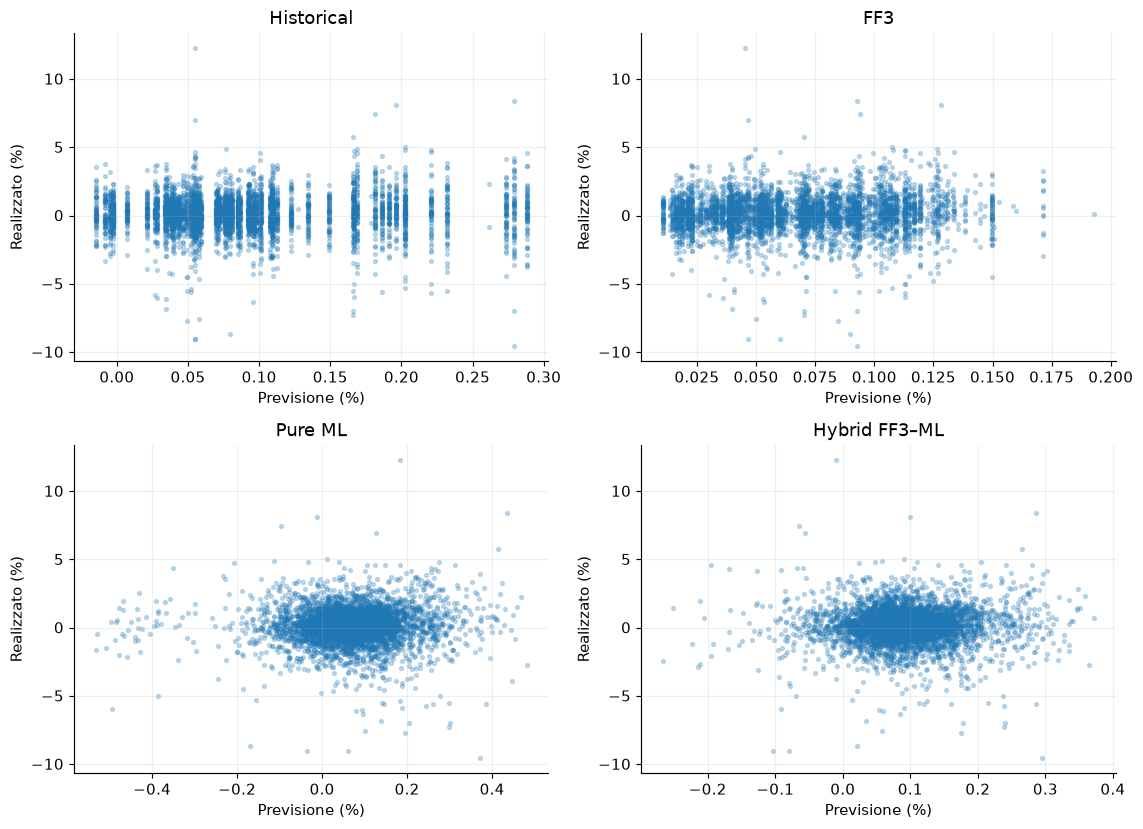

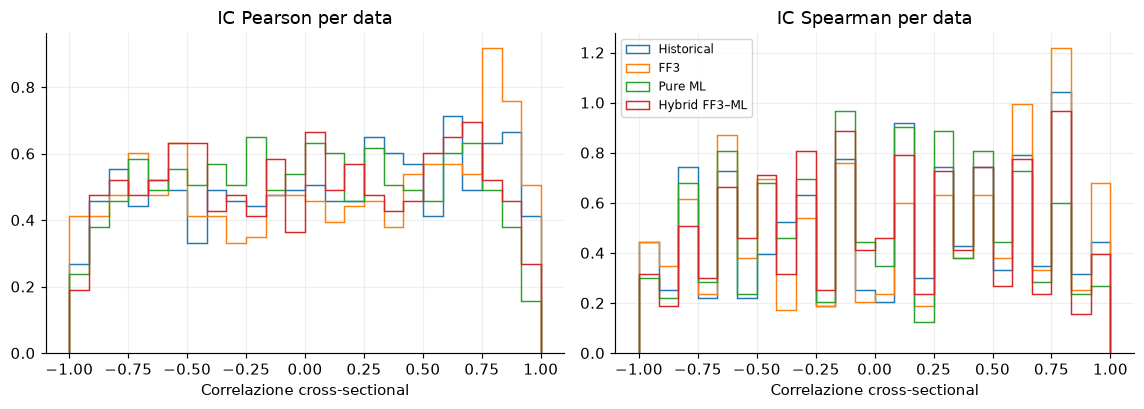

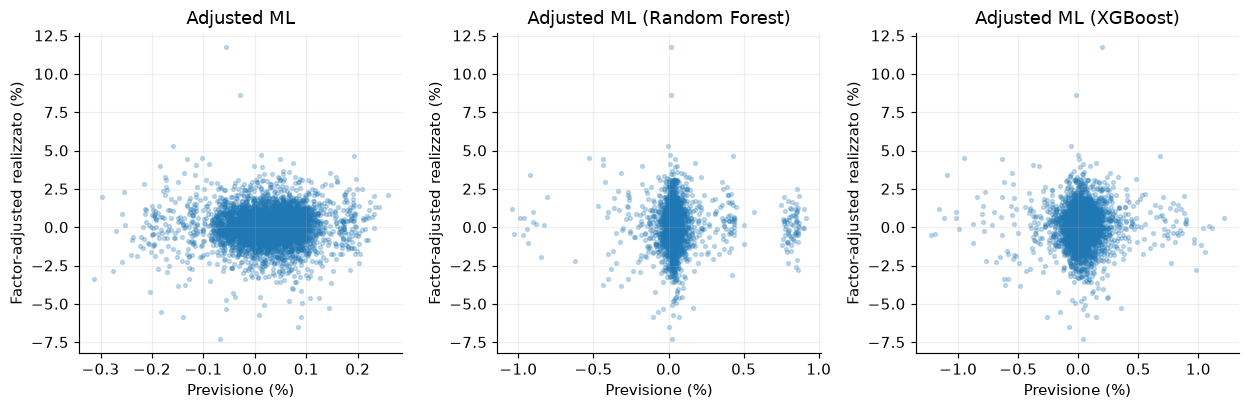

In [5]:
suffixes = ["", " (Random Forest)", " (XGBoost)"]
total_models = [*PRIMARY, *(s+t for t in suffixes[1:] for s in ("Pure ML", "Hybrid FF3–ML"))]
adjusted_models = ["Adjusted zero", "Adjusted mean", *("Adjusted ML"+t for t in suffixes)]
total, ic = forecast_metrics(result.forecasts, "target", total_models, "Historical")
matched_total, _ = forecast_metrics(result.forecasts.dropna(subset=["adjusted"]), "target",
                                    total_models, "Historical")
adjusted, adj_ic = forecast_metrics(result.forecasts, "adjusted", adjusted_models, "Adjusted zero")
display(out.table("forecast_total", total).round(6))
display(out.table("forecast_total_factor_matched", matched_total).round(6))
display(out.table("forecast_adjusted", adjusted).round(6))
display(out.table("ic_distribution", ic.groupby("Model")[["pearson", "spearman"]].describe()).round(3))
out.table("ic_by_date", ic)
out.table("adjusted_ic_by_date", adj_ic)
forecast_figures(out, result.forecasts, ic)

## 5. Allocazione e quantità ex ante

Per tutti i Maximum Sharpe risolviamo $\max_w(w^\top\mu-r_f)/\sqrt{w^\top\Sigma w}$ con $\sum_iw_i=1$ e $0\le w_i\le0{,}40$. $\mu$ è la previsione quotidiana moltiplicata per 252 e $\Sigma$ è la covarianza Ledoit–Wolf dei rendimenti osservati nel training moltiplicata per 252. Il risk-free annuale è l’ultimo €STR pubblicato alla decisione, convertito da ACT/360 su 365 giorni, identico per tutti gli ottimizzatori alla stessa data. I pesi sono decisi alla chiusura di $t$ ed eseguiti alla successiva chiusura. La previsione giornaliera è un proxy del rendimento medio a cui attribuiamo validità nell’intervallo di detenzione. L’ipotesi è che il segnale sopravviva sia al ritardo di esecuzione sia alla frequenza trimestrale.

Equal Weight usa pesi fissi uguali, GMV minimizza $w^\top\Sigma w$, Risk Parity cerca contributi al rischio uguali e HRP ripartisce il rischio con clustering. I loro pesi dipendono dalle regole di allocazione e, dove previsto, dalle covarianze. I loro rendimenti attesi riportati usano $\mu$ storico. $HHI=\sum w_i^2$ e la numerosità effettiva è $1/HHI$. La frontiera Markowitz mostrata è relativa all’ultima decisione e alla specifica $\mu$. Il portafoglio è interamente investito in azioni e la leva è esclusa; la Capital Market Line presuppone una combinazione con l’attività priva di rischio fuori dal problema posto.

,Expected return,Expected volatility,Expected Sharpe,Maximum weight,HHI,Effective assets
Strategy,,,,,,
Historical,0.42732,0.17935,2.27337,0.38807,0.31588,3.16571
FF3,0.24806,0.15302,1.49311,0.33111,0.22879,4.37089
Pure ML,0.13870,0.16927,0.70371,0.40000,0.30639,3.26379
Hybrid FF3–ML,0.21759,0.15027,1.31764,0.40000,0.28282,3.53580
Equal Weight,0.32767,0.14799,2.08173,0.16667,0.16667,6.00000
GMV,0.20596,0.12545,1.48566,0.40000,0.28465,3.51311
Risk Parity,0.28466,0.13556,1.95539,0.23706,0.17767,5.62845
HRP,0.24802,0.13002,1.75685,0.24427,0.20485,4.88166


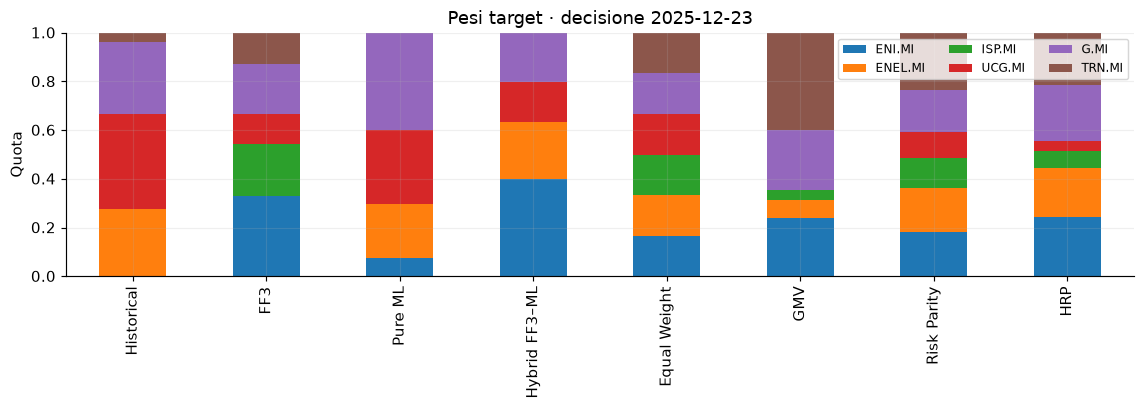

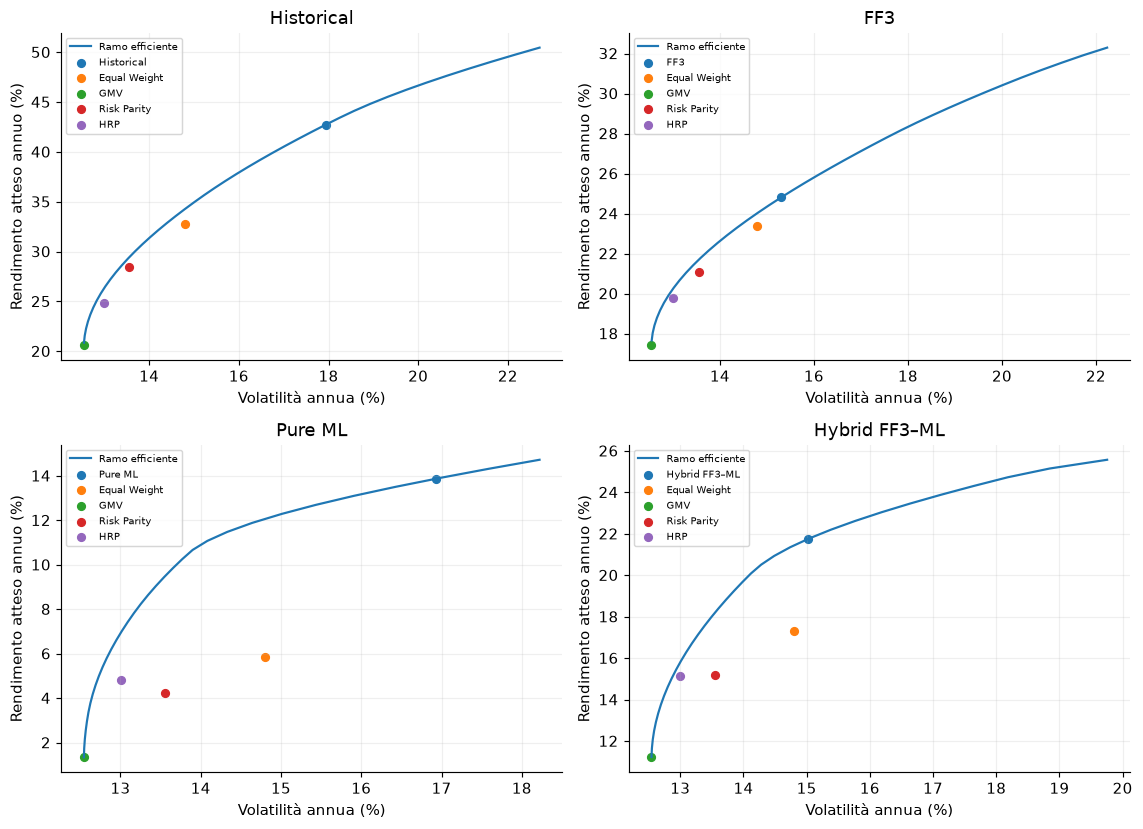

,ENI.MI,ENEL.MI,ISP.MI,UCG.MI,G.MI,TRN.MI
Historical,0.0000,0.2774,0.0000,0.3881,0.2945,0.0400
FF3,0.3311,0.0000,0.2130,0.1203,0.2066,0.1290
Pure ML,0.0756,0.2222,0.0000,0.3021,0.4000,0.0000
Hybrid FF3–ML,0.4000,0.2353,0.0000,0.1605,0.2042,0.0000
Equal Weight,0.1667,0.1667,0.1667,0.1667,0.1667,0.1667
GMV,0.2383,0.0739,0.0415,0.0000,0.2463,0.4000
Risk Parity,0.1837,0.1777,0.1253,0.1042,0.1719,0.2371
HRP,0.2443,0.2002,0.0717,0.0408,0.2298,0.2133


ENI.MI   ENEL.MI    ISP.MI    UCG.MI      G.MI  \
Strategy   Rebalance date                                                     
Historical 2023-01-03      0.400000  0.000000  0.000000  0.200000  0.000000   
           2023-03-31      0.171136  0.000000  0.000000  0.373366  0.055499   
           2023-07-03      0.230772  0.000000  0.000000  0.400000  0.036161   
           2023-09-29      0.400000  0.000000  0.000000  0.332697  0.218050   
           2023-12-29      0.391820  0.000000  0.000000  0.400000  0.000000   
...                             ...       ...       ...       ...       ...   
HRP        2024-12-27      0.237249  0.183269  0.070556  0.041589  0.256732   
           2025-03-28      0.197805  0.192978  0.100897  0.113187  0.184171   
           2025-06-30      0.237604  0.179867  0.081383  0.047319  0.263569   
           2025-09-26      0.241383  0.187265  0.077740  0.045663  0.251562   
           2025-12-29      0.244273  0.200178  0.071682  0.040761  0.229811   

                             TRN.MI  
Strategy   Rebalance date            
Historical 2023-01-03      0.400000  
           2023-03-31      0.400000  
           2023-07-03      0.333067  
           2023-09-29      0.049253  
           2023-12-29      0.208180  
...                             ...  
HRP        2024-12-27      0.210604  
           2025-03-28      0.210962  
           2025-06-30      0.190258  
           2025-09-26      0.196388  
           2025-12-29      0.213296  

[104 rows x 6 columns]

In [6]:
latest = result.ex_ante.index.get_level_values("Decision").max()
out.table("ex_ante_history", result.ex_ante)
display(result.ex_ante.loc[latest].round(5))
display(allocations(out, result, cfg).round(4))
weights = pd.concat(result.weights, names=["Strategy", "Rebalance date"])
out.table("weight_history", weights)

## 6. Walk-forward e performance realizzata

Il motore originale detiene quantità frazionarie costanti fra rebalance. Il drift deriva da $w_{i,t}\propto q_iP_{i,t}$; gli ordini confrontano le quantità effettive con le nuove quantità target. La simulazione parte da €10.000, investe alla chiusura successiva al segnale e applica 15 punti base per euro comprato o venduto. Il primo costo di entrata confluisce nel primo rendimento di detenzione. I rebalance avvengono ogni 63 sedute e il capitale scorre senza reset annuali. L’indice benchmark è un riferimento teorico. L’ETF del confronto supplementare incorpora le spese del fondo. Per entrambi si escludono i costi di esecuzione simulati per le strategie.

$V_T/V_0=\prod_t(1+r_t)$, $CAGR=(V_T/V_0)^{252/n}-1$. Media aritmetica e intercette si moltiplicano per 252; le deviazioni standard per $\sqrt{252}$. Sharpe e Sortino usano l’eccesso sull’€STR; Sortino usa il secondo momento delle deviazioni negative rispetto a zero. Il Calmar è il rapporto tra CAGR e drawdown massimo in valore assoluto. VaR ed ES sono perdite giornaliere storiche al 95%. Tracking Error e Information Ratio usano rendimenti attivi rispetto al benchmark del relativo confronto. Per Jensen regrediamo il rendimento in eccesso su quello in eccesso del benchmark, per l’alpha FF3 sui fattori EUR. Turnover è la media per ribilanciamento della somma di acquisti e vendite sul capitale pre-trade, incluso l’ingresso. Prezzi di chiusura rettificati, azioni frazionarie e costi lineari sono approssimazioni.

,Sessions,Cumulative return,CAGR,Annual arithmetic return,Volatility,Sharpe,Sortino,Calmar,Max drawdown,VaR 95% daily (loss),ES 95% daily (loss),Tracking error,Information ratio,Jensen alpha annual,FF3 alpha annual,Mean turnover per trade,Costs EUR
Strategy,,,,,,,,,,,,,,,,,
Historical,757,1.6164,0.3774,0.3366,0.1797,1.7043,2.4533,2.1810,-0.1730,0.0178,0.0260,0.0913,1.3234,0.1263,0.0983,0.4276,127.2526
FF3,757,1.5479,0.3653,0.3277,0.1793,1.6588,2.3130,2.0087,-0.1818,0.0168,0.0279,0.0891,1.2572,0.1164,0.0639,0.3623,114.8476
Pure ML,757,1.1671,0.2936,0.2735,0.1780,1.3660,1.9418,1.7807,-0.1649,0.0150,0.0259,0.1188,0.4867,0.0864,0.0656,1.0469,300.6838
Hybrid FF3–ML,757,1.3318,0.3256,0.2930,0.1483,1.7718,2.5867,2.1502,-0.1514,0.0137,0.0213,0.1087,0.7110,0.1330,0.1232,1.0595,317.0877
Equal Weight,757,1.5459,0.3649,0.3226,0.1504,1.9433,2.7339,2.4800,-0.1471,0.0131,0.0232,0.0723,1.4794,0.1362,0.1133,0.1262,30.7861
GMV,757,0.8473,0.2267,0.2124,0.1265,1.4395,2.0443,1.9020,-0.1192,0.0109,0.0182,0.1200,-0.0273,0.0836,0.0793,0.1679,40.1510
Risk Parity,757,1.2803,0.3157,0.2842,0.1383,1.8353,2.5663,2.3246,-0.1358,0.0125,0.0213,0.0816,0.8392,0.1157,0.0998,0.1319,31.4213
HRP,757,1.0780,0.2757,0.2526,0.1336,1.6627,2.3149,2.0364,-0.1354,0.0113,0.0202,0.0918,0.4017,0.0952,0.0808,0.1926,48.2271
FTSE MIB,757,0.8393,0.2249,0.2157,0.1593,1.1626,1.6007,1.2792,-0.1758,0.0155,0.0241,0.0000,NaN,-0.0000,0.0439,NaN,0.0000


Sessions  Cumulative return    CAGR  \
Year Strategy                                             
2023 Historical          252             0.3020  0.3020   
     FF3                 252             0.3271  0.3271   
     Pure ML             252             0.2716  0.2716   
     Hybrid FF3–ML       252             0.3045  0.3045   
     Equal Weight        252             0.3372  0.3372   
     GMV                 252             0.1990  0.1990   
     Risk Parity         252             0.2935  0.2935   
     HRP                 252             0.2440  0.2440   
     FTSE MIB            252             0.2421  0.2421   
2024 Historical          253             0.2592  0.2580   
     FF3                 253             0.3044  0.3030   
     Pure ML             253             0.2288  0.2278   
     Hybrid FF3–ML       253             0.2586  0.2575   
     Equal Weight        253             0.2926  0.2913   
     GMV                 253             0.1718  0.1710   
     Risk Parity         253             0.2378  0.2367   
     HRP                 253             0.1974  0.1966   
     FTSE MIB            253             0.1263  0.1258   
2025 Historical          252             0.5959  0.5959   
     FF3                 252             0.4718  0.4718   
     Pure ML             252             0.3870  0.3870   
     Hybrid FF3–ML       252             0.4202  0.4202   
     Equal Weight        252             0.4728  0.4728   
     GMV                 252             0.3148  0.3148   
     Risk Parity         252             0.4242  0.4242   
     HRP                 252             0.3951  0.3951   
     FTSE MIB            252             0.3147  0.3147   

                    Annual arithmetic return  Volatility  Sharpe  Sortino  \
Year Strategy                                                               
2023 Historical                       0.2774      0.1633  1.5026   2.1644   
     FF3                              0.3012      0.1897  1.4194   1.9687   
     Pure ML                          0.2610      0.2029  1.1285   1.5755   
     Hybrid FF3–ML                    0.2749      0.1345  1.8069   2.7883   
     Equal Weight                     0.3035      0.1592  1.7052   2.4106   
     GMV                              0.1892      0.1239  1.2683   1.8500   
     Risk Parity                      0.2680      0.1450  1.6274   2.2991   
     HRP                              0.2282      0.1403  1.3986   1.9559   
     FTSE MIB                         0.2290      0.1556  1.2652   1.7834   
2024 Historical                       0.2426      0.1610  1.2780   1.8419   
     FF3                              0.2788      0.1674  1.4460   2.0787   
     Pure ML                          0.2146      0.1371  1.2962   1.9587   
     Hybrid FF3–ML                    0.2384      0.1354  1.4886   2.2489   
     Equal Weight                     0.2653      0.1382  1.6532   2.4167   
     GMV                              0.1652      0.1208  1.0617   1.5834   
     Risk Parity                      0.2208      0.1284  1.4324   2.0908   
     HRP                              0.1869      0.1220  1.2299   1.8045   
     FTSE MIB                         0.1283      0.1403  0.6506   0.8918   
2025 Historical                       0.4902      0.2108  2.2208   3.1966   
     FF3                              0.4032      0.1807  2.1089   2.8937   
     Pure ML                          0.3451      0.1879  1.7187   2.4278   
     Hybrid FF3–ML                    0.3659      0.1723  1.9956   2.7772   
     Equal Weight                     0.3994      0.1536  2.4564   3.3492   
     GMV                              0.2830      0.1346  1.9382   2.6070   
     Risk Parity                      0.3640      0.1414  2.4181   3.2473   
     HRP                              0.3428      0.1383  2.3193   3.1035   
     FTSE MIB                         0.2901      0.1801  1.4877   2.0240   

                    Calmar  Max drawdown  VaR 95% daily (loss)  \
Year Str

Confronto CSMIB.MI su sedute contigue fino al 2025-10-23


,Sessions,Cumulative return,CAGR,Annual arithmetic return,Volatility,Sharpe,Sortino,Calmar,Max drawdown,VaR 95% daily (loss),ES 95% daily (loss),Tracking error,Information ratio,Jensen alpha annual,FF3 alpha annual,Mean turnover per trade,Costs EUR
Strategy,,,,,,,,,,,,,,,,,
Historical,712,1.3612,0.3554,0.3209,0.1820,1.5933,2.2847,2.0538,-0.1730,0.0178,0.0263,0.0938,0.7099,0.0736,0.0975,0.4524,122.2090
FF3,712,1.3194,0.3469,0.3145,0.1817,1.5610,2.1639,1.9076,-0.1818,0.0168,0.0284,0.0924,0.6524,0.0666,0.0659,0.3452,93.4071
Pure ML,712,0.9661,0.2703,0.2557,0.1802,1.2469,1.7616,1.6394,-0.1649,0.0157,0.0263,0.1216,0.0114,0.0370,0.0602,1.0840,281.3249
Hybrid FF3–ML,712,1.0998,0.3003,0.2737,0.1480,1.6401,2.3752,1.9831,-0.1514,0.0137,0.0213,0.1095,0.1769,0.0885,0.1144,1.0419,273.0422
Equal Weight,712,1.3587,0.3549,0.3157,0.1530,1.8612,2.6052,2.4119,-0.1471,0.0132,0.0237,0.0740,0.8288,0.0959,0.1181,0.1357,30.2960
GMV,712,0.7592,0.2213,0.2083,0.1284,1.3809,1.9482,1.8570,-0.1192,0.0113,0.0186,0.1203,-0.3827,0.0570,0.0801,0.1724,37.0223
Risk Parity,712,1.1342,0.3078,0.2784,0.1407,1.7586,2.4461,2.2658,-0.1358,0.0130,0.0218,0.0825,0.2920,0.0799,0.1038,0.1401,30.2749
HRP,712,0.9559,0.2680,0.2468,0.1359,1.5880,2.1990,1.9796,-0.1354,0.0115,0.0207,0.0923,-0.0809,0.0613,0.0831,0.2033,46.2613
FTSE MIB,712,0.9766,0.2727,0.2543,0.1611,1.3861,1.9291,1.5503,-0.1759,0.0155,0.0243,0.0000,NaN,0.0000,0.0863,NaN,0.0000


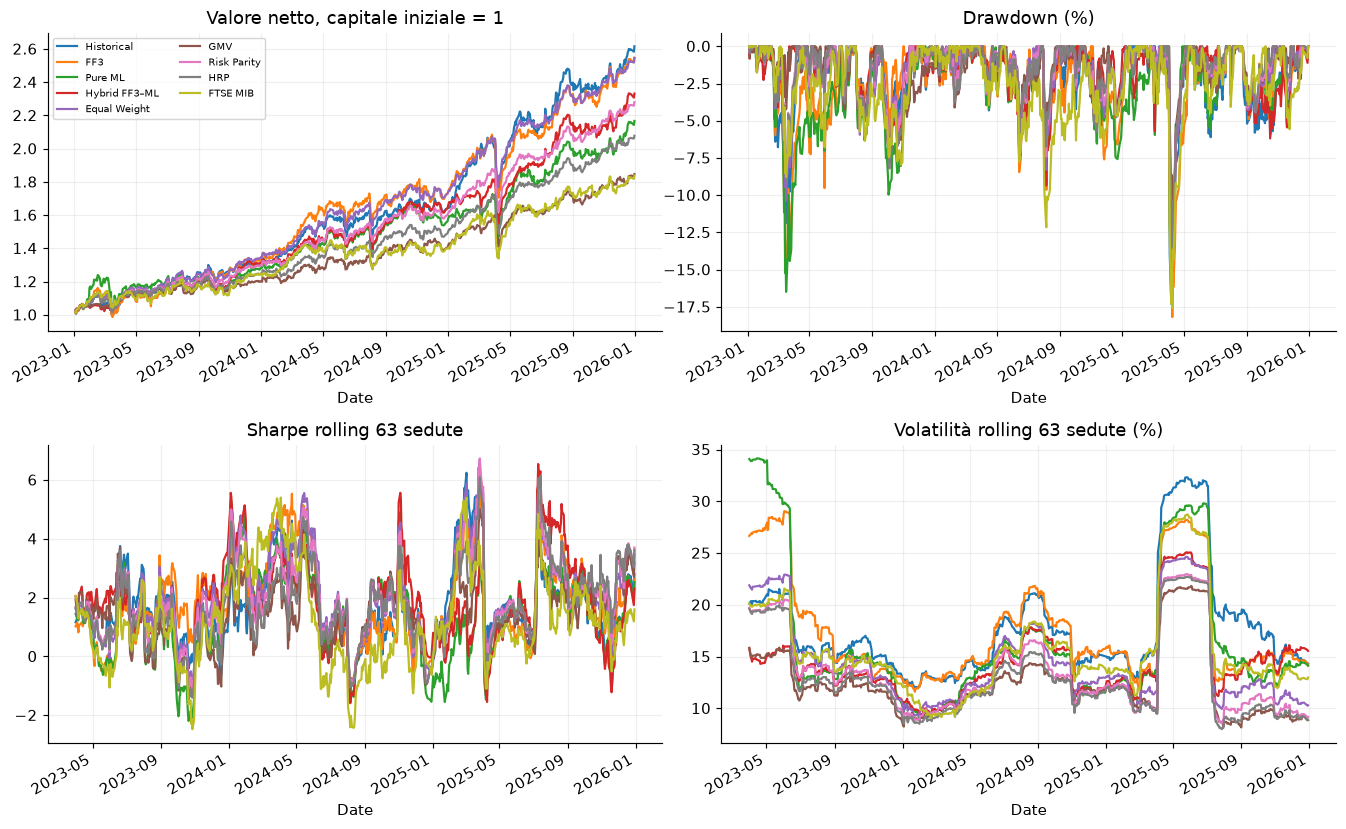

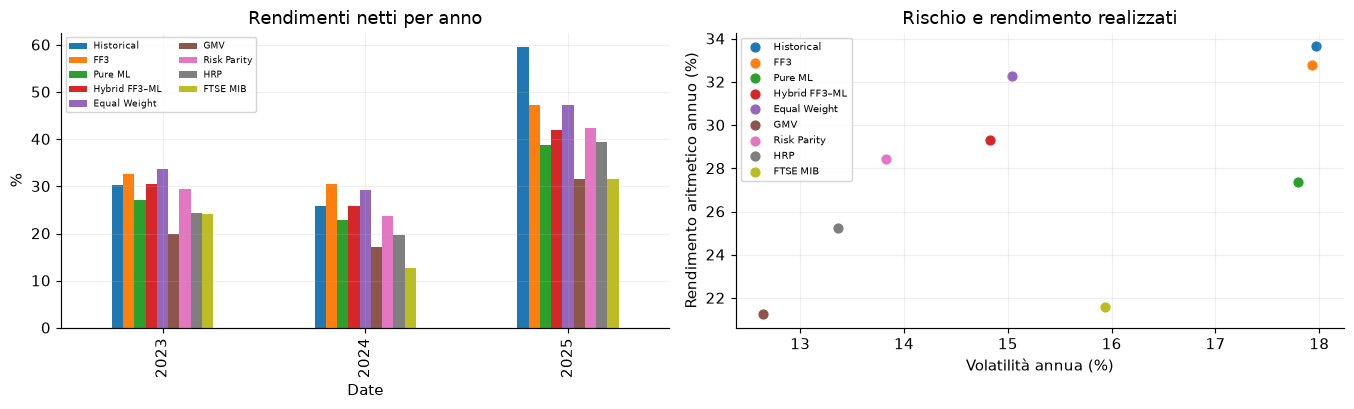

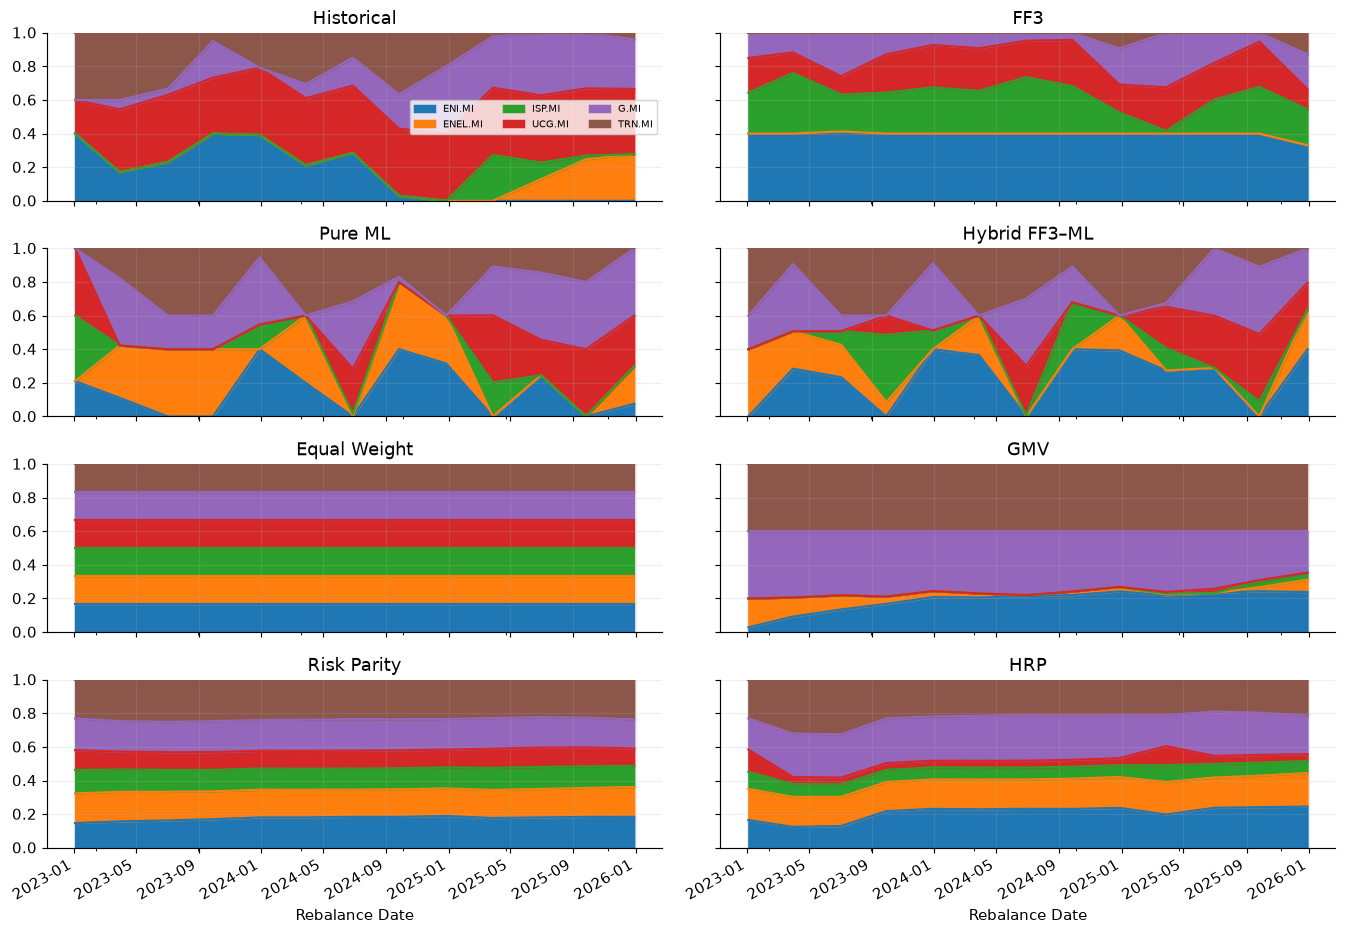

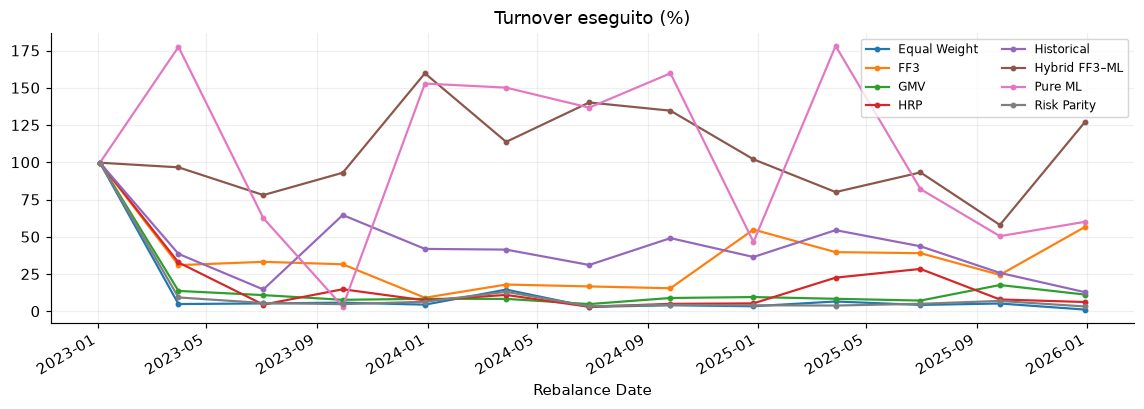

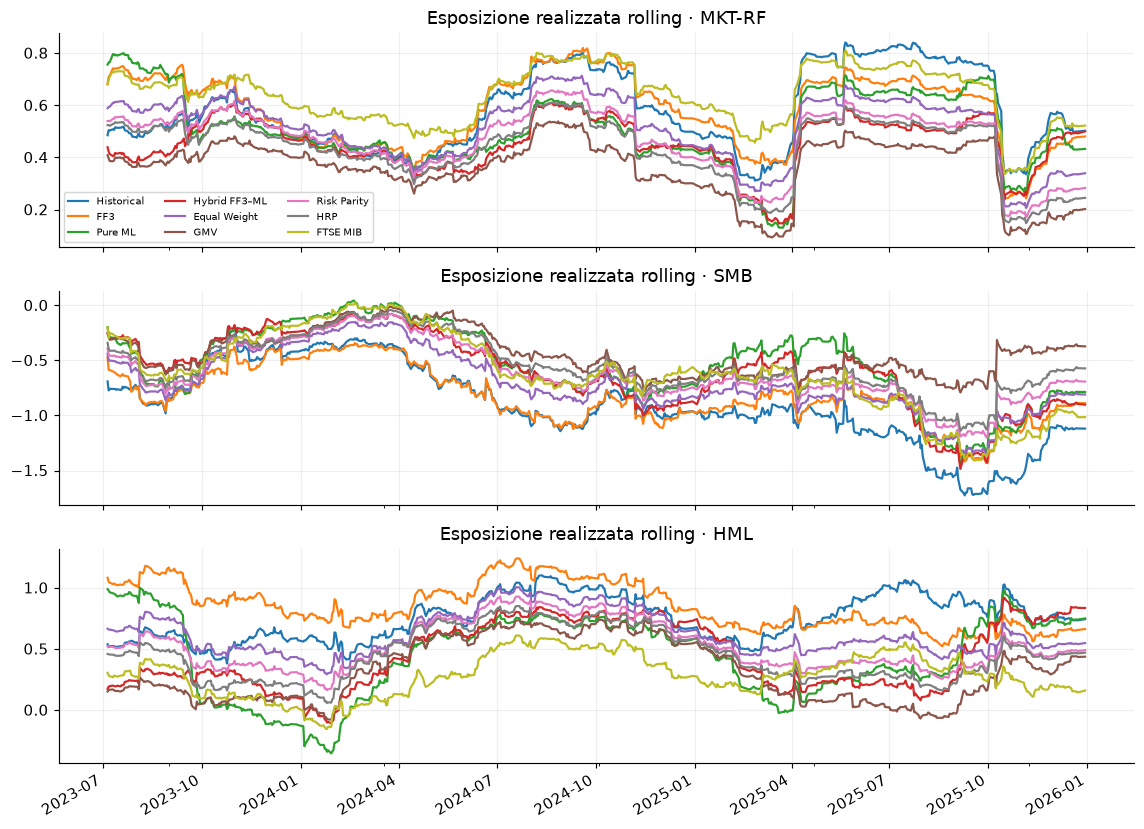

In [7]:
initial = result.fit_audit.Execution.iloc[0]
perf = performance(result.net, panel, result.trades, cfg.hac_lags, initial_date=initial)
display(out.table("performance_oos", perf).round(4))
years = {}
for year, sample in result.net.groupby(result.net.index.year):
    years[year] = performance(sample, panel, result.trades, cfg.hac_lags,
                              initial_date=initial if year == initial.year else sample.index[0])
display(out.table("performance_calendar_year", pd.concat(years, names=["Year"])).round(4))
exposures = portfolio_exposures(result.net, panel)
out.table("portfolio_factor_exposures", exposures)
out.table("trade_log", result.trades)
out.table("daily_net_returns", result.net)
out.table("daily_gross_returns", result.gross)
if "aux:CSMIB.MI" in panel:
    proxy = panel["aux:CSMIB.MI"].pct_change(fill_method=None).reindex(result.net.index)
    contiguous = proxy.notna().cummin()
    if contiguous.sum() >= 40:
        matched_etf = result.net.loc[contiguous].copy()
        matched_etf[BENCH] = proxy.loc[contiguous]
        print(f"Confronto CSMIB.MI su sedute contigue fino al {matched_etf.index[-1].date()}")
        display(out.table("performance_matched_total_return_proxy", performance(
            matched_etf, panel, result.trades, cfg.hac_lags, initial_date=initial)).round(4))
realized_figures(out, result, panel, perf, exposures)

## 7. Quattro ipotesi economiche

- **H1.** FF3 migliora l’efficienza rispetto a Historical.
- **H2.** Pure ML migliora l’efficienza rispetto a Historical.
- **H3.** Hybrid FF3–ML migliora l’efficienza rispetto a FF3.
- **H4.** Hybrid FF3–ML migliora l’efficienza rispetto a Pure ML.

L’unità è il differenziale appaiato di rendimento netto per seduta. Testiamo la media $\delta$ nel modello $d_t=\delta+u_t$ con HAC a 10 lag e $p$ bilaterale. Holm controlla l’errore familiare sui quattro test delle medie. Per lo Sharpe riportiamo intervalli percentili marginali al 95% via bootstrap circolare a blocchi appaiati di 21 sedute, mantenendo lo stesso indice per i due rendimenti in eccesso. Le differenze di volatilità, drawdown, turnover, costi e performance lorda/netta descrivono la natura economica del risultato. In una regressione esplorativa sui differenziali netti abbiniamo anche beta e contributi medi $\Delta\widehateta_j\overline F_j$, con l’alpha differenziale e il suo intervallo HAC. Il bootstrap approssima la dipendenza per blocchi e la sua precisione resta limitata dal numero di regimi osservati.

In [8]:
hypotheses = inference(result, panel, cfg)
display(out.table("hypotheses", hypotheses).round(5))
attribution = differential_attribution(result, panel, hypotheses, cfg.hac_lags)
display(out.table("differential_factor_attribution", attribution).round(5))

,Left,Right,Daily mean Δ,Annual mean Δ,HAC SE,HAC t,HAC p,Sharpe Δ,Sharpe CI low,Sharpe CI high,Volatility Δ,Max drawdown Δ,Turnover Δ,Gross cumulative Δ,Net cumulative Δ,Costs EUR Δ,Holm p
Hypothesis,,,,,,,,,,,,,,,,,
H1,FF3,Historical,-0.00004,-0.00888,0.00017,-0.21097,0.83297,-0.04550,-0.48965,0.44097,-0.00042,-0.00880,-0.06536,-0.07242,-0.06857,-12.40500,1.0
H2,Pure ML,Historical,-0.00025,-0.06308,0.00026,-0.98150,0.32666,-0.33832,-1.10702,0.39875,-0.00176,0.00814,0.61930,-0.42652,-0.44934,173.43120,1.0
H3,Hybrid FF3–ML,FF3,-0.00014,-0.03469,0.00025,-0.54222,0.58782,0.11300,-0.69673,0.95346,-0.03103,0.03042,0.69721,-0.18546,-0.21611,202.24013,1.0
H4,Hybrid FF3–ML,Pure ML,0.00008,0.01951,0.00025,0.30725,0.75874,0.40582,-0.42026,1.29543,-0.02970,0.01348,0.01256,0.16864,0.16466,16.40393,1.0


,Sessions,Annual net spread matched,Annual differential alpha,Annual alpha HAC SE,Annual alpha CI low,Annual alpha CI high,Alpha p (exploratory),Market beta Δ,SMB beta Δ,HML beta Δ,Market contribution annual,SMB contribution annual,HML contribution annual
Hypothesis,,,,,,,,,,,,,
H1,743,-0.01686,-0.03439,0.04438,-0.12151,0.05273,0.43867,0.02110,0.10368,0.17677,0.00193,-0.00649,0.02208
H2,743,-0.06684,-0.03269,0.07045,-0.17099,0.10561,0.64278,-0.01389,0.32261,-0.10150,-0.00127,-0.02020,-0.01268
H3,743,-0.02727,0.05927,0.06418,-0.06672,0.18527,0.35603,-0.15435,0.17447,-0.49198,-0.01415,-0.01093,-0.06146
H4,743,0.02272,0.05757,0.07531,-0.09027,0.20542,0.44481,-0.11936,-0.04446,-0.21371,-0.01094,0.00278,-0.02670


## 8. Sensibilità

Specifiche definite prima del fit. Si ripete il confronto sugli intervalli annuali contigui senza liquidare i portafogli. Si riclassificano le sedute usando volatilità benchmark a 63 sedute fino alla chiusura precedente, con soglia mediana pre-test, e mercato rialzista o ribassista in base al segno del rendimento composto benchmark nelle 63 sedute precedenti. Le statistiche di percorso sono omesse per i regimi non contigui. Nei replay si variano, singolarmente, costo (0/30 bps), frequenza (21/126 sedute) e training (504 anziché 756 sedute). Il target ibrido conserva la sua finestra beta annua. Le analisi per sottocampioni hanno minore potenza e sono descrittive. Le specifiche restano tutte visibili.

In [9]:
sensitivity, threshold = robustness(result, panel, cfg)
print(f"Soglia volatilità benchmark fissata prima del test: {threshold:.2%}")
display(out.table("robustness", sensitivity).round(4))

Soglia volatilità benchmark fissata prima del test: 21.52%


Sessions  Cumulative return  \
Specification Strategy                                     
Cost 0 bps    Historical          757             1.6384   
              FF3                 757             1.5659   
              Pure ML             757             1.2118   
              Hybrid FF3–ML       757             1.3805   
              Equal Weight        757             1.5522   
...                               ...                ...   
Bear          Equal Weight        141                NaN   
              GMV                 141                NaN   
              Risk Parity         141                NaN   
              HRP                 141                NaN   
              FTSE MIB            141                NaN   

                             Annual arithmetic return  Volatility  Sharpe  \
Specification Strategy                                                      
Cost 0 bps    Historical                       0.3394      0.1798  1.7193   
              FF3                              0.3301      0.1793  1.6716   
              Pure ML                          0.2803      0.1781  1.4033   
              Hybrid FF3–ML                    0.2999      0.1485  1.8161   
              Equal Weight                     0.3235      0.1505  1.9478   
...                                               ...         ...     ...   
Bear          Equal Weight                     0.5034      0.1846  2.5373   
              GMV                              0.3759      0.1635  2.0861   
              Risk Parity                      0.4588      0.1747  2.4252   
              HRP                              0.4481      0.1697  2.4336   
              FTSE MIB                         0.4950      0.1927  2.3856   

                             Max drawdown  Mean turnover per trade  Costs EUR  
Specification Strategy                                                         
Cost 0 bps    Historical          -0.1724                   0.4277        0.0  
              FF3                 -0.1813                   0.3625        0.0  
              Pure ML             -0.1649                   1.0479        0.0  
              Hybrid FF3–ML       -0.1514                   1.0604        0.0  
              Equal Weight        -0.1471                   0.1264        0.0  
...                                   ...                      ...        ...  
Bear          Equal Weight            NaN                      NaN        NaN  
              GMV                     NaN                      NaN        NaN  
              Risk Parity             NaN                      NaN        NaN  
              HRP                     NaN                      NaN        NaN  
              FTSE MIB                NaN                      NaN        NaN  

[108 rows x 8 columns]

## 9. Controlli di riproducibilità

La verifica su un prefisso rimuove circa metà del periodo out-of-sample dalla tabella d’ingresso, ricostruisce i target, ripete il fit Ridge e confronta previsioni, pesi delle esecuzioni precedenti alla data finale e rendimenti sul tratto comune. Sono controllati anche calendario, costi, annualizzazione e corrispondenza con il benchmark. Il controllo di prefisso verifica la causalità interna della pipeline sulla versione dei dati salvata.

In [10]:
import hashlib
import importlib.metadata as metadata

assert result.fit_audit["Last ML label"].le(result.fit_audit["Last factor"]).all()
assert result.fit_audit["Last factor"].le(result.fit_audit.Decision - pd.DateOffset(months=2)).all()
assert result.target_audit["Beta last factor"].le(
    result.target_audit["Beta decision"] - pd.DateOffset(months=2)).all()
assert (result.fit_audit.Decision < result.fit_audit.Execution).all()
assert np.allclose(result.net[BENCH], panel.loc[result.net.index, "return:"+cfg.benchmark])
assert np.allclose(perf.Volatility, result.net.std()*np.sqrt(ANNUAL))
assert np.allclose(perf["Annual arithmetic return"], result.net.mean()*ANNUAL)
assert (result.trades["Total Cost"] >= 0).all()
assert (result.trades["Total Cost"].groupby(result.trades.Strategy).sum() > 0).all() or cfg.cost_bps == 0
cut = result.net.index[len(result.net)//2]
prefix = run(panel.loc[:cut], cfg, only_primary=True)
keys = ["label_end", "ticker"]
expected = result.forecasts.set_index(keys).loc[:cut, list(PRIMARY)].sort_index()
observed = prefix.forecasts.set_index(keys)[list(PRIMARY)].sort_index()
pd.testing.assert_frame_equal(expected, observed, check_exact=False, rtol=1e-9, atol=1e-12)
for name, w in prefix.weights.items():
    pd.testing.assert_frame_equal(w, result.weights[name].loc[w.index], check_exact=False)
# Boundary execution would charge the next rebalance cost only in the full run.
pd.testing.assert_frame_equal(prefix.net.iloc[:-1], result.net.loc[prefix.net.index[:-1]],
                              check_exact=False, rtol=1e-9, atol=1e-12)
digest = hashlib.sha256((study / "data" / "market_panel.parquet").read_bytes()).hexdigest()
source_files = [
    *[repo / "src" / (name+".py") for name in (
        "backtest", "data", "factor_currency", "factor_eur", "fama_french", "forward_mc",
        "ml_estimators", "ml_forecasting", "optimization", "returns", "time_series_market", "transaction_costs")],
    *study.glob("*.py"),
]
source_manifest = pd.DataFrame([
    (str(p.relative_to(study) if p.is_relative_to(study) else p.relative_to(repo)),
     hashlib.sha256(p.read_bytes()).hexdigest()) for p in sorted(source_files)
], columns=["File", "SHA-256"]).set_index("File")
out.table("source_manifest", source_manifest)
print(f"Controlli superati. Prefisso fino al {cut.date()}. SHA-256 del Parquet: {digest}")
display(pd.Series({p: metadata.version(p) for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "statsmodels",
    "yfinance", "exchange-calendars", "pyarrow", "matplotlib", "ipykernel"
)}, name="Versione"))

Controlli superati. Prefisso fino al 2024-07-01. SHA-256 del Parquet: a0ad97af2c29a7548605705364666b390b02f71a14967d65d07543556b1dc714


numpy                  2.5.3
pandas                 3.0.6
scipy                 1.18.1
scikit-learn           1.9.1
xgboost                3.4.1
statsmodels           0.15.0
yfinance               1.7.0
exchange-calendars    4.13.3
pyarrow               25.0.1
matplotlib            3.11.2
ipykernel              7.4.0
Name: Versione, dtype: str

## 10. Interpretazione economica

Il $R^2$ della regressione sui fattori osservati e l’accuratezza della previsione misurano due problemi diversi. Gli alpha storici possono incorporare errori di specificazione, rischi omessi o rumore. La loro significatività descrittiva va confrontata con la prevedibilità della componente factor-adjusted e con il contributo economico all’allocazione.

In [11]:
alpha = coefs.xs("Alpha", level="Term")
def describe_h(label, row):
    return (f"**{label}.** Δ Sharpe {row['Sharpe Δ']:+.2f} "
            f"(IC 95% [{row['Sharpe CI low']:+.2f}, {row['Sharpe CI high']:+.2f}]), "
            f"Δ rendimento cumulato lordo {row['Gross cumulative Δ']*100:+.2f} pp "
            f"e netto {row['Net cumulative Δ']*100:+.2f} pp. "
            f"p HAC corretto Holm per il differenziale medio {row['Holm p']:.3f}.")
lines = [
    f"Il FF3 spiega tra il {alpha['R²'].min():.1%} e il {alpha['R²'].max():.1%} "
    f"della variazione in-sample per titolo. L’alpha è significativo al 5% nominale "
    f"per {(alpha['p-value'] < .05).sum()} titoli su {len(alpha)}.",
    f"Fuori campione, l’R² rispetto alla media storica è {total.loc['FF3','OOS R²']:.3%} per FF3, "
    f"{total.loc['Pure ML','OOS R²']:.3%} per Pure ML e {total.loc['Hybrid FF3–ML','OOS R²']:.3%} "
    "per Hybrid FF3–ML. I tre modelli ML per il target factor-adjusted hanno i risultati seguenti "
    "rispetto a zero e alla semplice media del target.",
    *[f"- {name}: RMSE {adjusted.loc[name, 'RMSE']:.4%}. "
      f"R² rispetto a zero {adjusted.loc[name, 'OOS R²']:.3%}."
      for name in adjusted.index],
    *[describe_h(label, row) for label, row in hypotheses.iterrows()],
    f"Per H3, la volatilità annualizzata differisce di {hypotheses.loc['H3','Volatility Δ']*100:+.2f} pp. "
    f"Il contributo fattoriale medio sul campione abbinato è "
    f"{attribution.loc['H3'].filter(like='contribution annual').sum():+.2%} annuo. "
    f"L’alpha differenziale stimato è {attribution.loc['H3','Annual differential alpha']:+.2%} "
    f"(IC 95% [{attribution.loc['H3','Annual alpha CI low']:+.2%}, "
    f"{attribution.loc['H3','Annual alpha CI high']:+.2%}]).",
    f"L’alpha FF3 annualizzato sul portafoglio netto ibrido è "
    f"{perf.loc['Hybrid FF3–ML','FF3 alpha annual']:.2%}. I grafici delle esposizioni realizzate "
    "mostrano come i beta variano nel tempo; un’intercetta unica non separa con precisione "
    "il contributo predittivo da esposizioni dinamiche, fattori omessi e costi.",
]
display(Markdown("\n\n".join(lines)))

Il FF3 spiega tra il 20.9% e il 56.6% della variazione in-sample per titolo. L’alpha è significativo al 5% nominale per 0 titoli su 6.

Fuori campione, l’R² rispetto alla media storica è -0.033% per FF3, -0.289% per Pure ML e -0.078% per Hybrid FF3–ML. I tre modelli ML per il target factor-adjusted hanno i risultati seguenti rispetto a zero e alla semplice media del target.

- Adjusted zero: RMSE 1.1464%. R² rispetto a zero 0.000%.

- Adjusted mean: RMSE 1.1466%. R² rispetto a zero -0.031%.

- Adjusted ML: RMSE 1.1467%. R² rispetto a zero -0.057%.

- Adjusted ML (Random Forest): RMSE 1.1521%. R² rispetto a zero -1.003%.

- Adjusted ML (XGBoost): RMSE 1.1544%. R² rispetto a zero -1.398%.

**H1.** Δ Sharpe -0.05 (IC 95% [-0.49, +0.44]), Δ rendimento cumulato lordo -7.24 pp e netto -6.86 pp. p HAC corretto Holm per il differenziale medio 1.000.

**H2.** Δ Sharpe -0.34 (IC 95% [-1.11, +0.40]), Δ rendimento cumulato lordo -42.65 pp e netto -44.93 pp. p HAC corretto Holm per il differenziale medio 1.000.

**H3.** Δ Sharpe +0.11 (IC 95% [-0.70, +0.95]), Δ rendimento cumulato lordo -18.55 pp e netto -21.61 pp. p HAC corretto Holm per il differenziale medio 1.000.

**H4.** Δ Sharpe +0.41 (IC 95% [-0.42, +1.30]), Δ rendimento cumulato lordo +16.86 pp e netto +16.47 pp. p HAC corretto Holm per il differenziale medio 1.000.

Per H3, la volatilità annualizzata differisce di -3.10 pp. Il contributo fattoriale medio sul campione abbinato è -8.65% annuo. L’alpha differenziale stimato è +5.93% (IC 95% [-6.67%, +18.53%]).

L’alpha FF3 annualizzato sul portafoglio netto ibrido è 12.32%. I grafici delle esposizioni realizzate mostrano come i beta variano nel tempo; un’intercetta unica non separa con precisione il contributo predittivo da esposizioni dinamiche, fattori omessi e costi.

Una differenza di RMSE può avere effetti piccoli o instabili sui pesi, perché l’ottimizzatore usa l’intero vettore dei rendimenti attesi e la covarianza. L’efficienza economica va quindi letta nelle differenze di Sharpe, rischio e costi, con i relativi intervalli. Il breve test, l’esposizione concentrata sull’Italia, la selezione dei superstiti, le revisioni del fornitore e l’assenza di rischio di esecuzione intraday limitano l’estensione delle conclusioni. Un intervallo che include zero lascia aperti vantaggi e svantaggi compatibili con i dati.

## Riferimenti

- Markowitz, H. (1952). *Portfolio Selection*. Journal of Finance, 7(1), 77–91. [DOI](https://doi.org/10.1111/j.1540-6261.1952.tb01525.x)
- Fama, E. F. e French, K. R. (1993). *Common Risk Factors in the Returns on Stocks and Bonds*. Journal of Financial Economics, 33(1), 3–56. [DOI](https://doi.org/10.1016/0304-405X(93)90023-5)
- Fama, E. F. e French, K. R. (2015). *A Five-Factor Asset Pricing Model*. Journal of Financial Economics, 116(1), 1–22. La specificazione più ampia motiva cautela nell’attribuire a un alpha FF3 il significato di rendimento anomalo. [Editore](https://www.sciencedirect.com/science/article/pii/S0304405X14002323)
- Gu, S., Kelly, B. e Xiu, D. (2020). *Empirical Asset Pricing via Machine Learning*. Review of Financial Studies, 33(5), 2223–2273. [DOI](https://doi.org/10.1093/rfs/hhaa009)
- Paleologo, G. A. (2025). *The Elements of Quantitative Investing*. Wiley. [Editore](https://www.wiley.com/en-gb/the-elements-of-quantitative-investing-p-9781394265466)
- Harvey, C. R., Liu, Y. e Zhu, H. (2016). *… and the Cross-Section of Expected Returns*. Review of Financial Studies, 29(1), 5–68. [DOI](https://doi.org/10.1093/rfs/hhv059)
- Jensen, T. I., Kelly, B., Malamud, S. e Pedersen, L. H. (2026). *Machine Learning and the Implementable Efficient Frontier*. Review of Financial Studies, 39(10), 3035–3078. [Editore](https://academic.oup.com/rfs/article/39/10/3035/8524346)
- *Quantitative Portfolio Optimization*, documento metodologico del repository, versione integrata 5.0 (ottobre 2026). Convenzioni per prezzi rettificati, 252 sedute, strategia Max Sharpe e walk-forward con quantità detenute. Quant_Portfolio_Optimizer_Paper.pdf.